In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
artists = pd.read_json('artists.jsonl', lines=True)
genres_to_filter = ['pop', 'trap', 'rap', 'rock', 'metal', 'hip hop']

In [3]:
def filter_genres(genre_list, regex_pattern):
    return [genre for genre in genre_list if pd.Series([genre]).str.contains(regex_pattern, regex=True).any()]


In [4]:
filtered_artists = pd.DataFrame()
filtered_genres_dict = {}
for genre in genres_to_filter:
    regex_pattern = fr'\b({genre})\b'

    artists['filtered_genres'] = artists['genres'].apply(lambda x: filter_genres(x, regex_pattern))
    one_genre = artists[artists['filtered_genres'].apply(lambda x: x != [])]
    one_genre.loc[:, 'genres'] = genre
    filtered_artists = pd.concat([filtered_artists, one_genre], ignore_index=True)

filtered_artists = filtered_artists.drop(columns=['filtered_genres'])

print(filtered_artists)

/tmp/ipykernel_77284/77786420.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return [genre for genre in genre_list if pd.Series([genre]).str.contains(regex_pattern, regex=True).any()]
/tmp/ipykernel_77284/77786420.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return [genre for genre in genre_list if pd.Series([genre]).str.contains(regex_pattern, regex=True).any()]


                          id                name   genres
0     7jVv8c5Fj3E9VhNjxT4snq           Lil Nas X      pop
1     0xRXCcSX89eobfrshSVdyu              MEDUZA      pop
2     4f7KfxeHq9BiylGmyXepGt      Tanishk Bagchi      pop
3     56mfhUDKa1vec6rSLZV5Eg           Jawsh 685      pop
4     6m6e7D2TnV0aYMllFFwMxu  Guilherme & Benuto      pop
...                      ...                 ...      ...
2277  50co4Is1HCEo8bhOyUWKpn          Young Thug  hip hop
2278  6U3ybJ9UHNKEdsH7ktGBZ7                 JID  hip hop
2279  1qQLhymHXFPtP5U8KNKsm6          Apache 207  hip hop
2280  6qgnBH6iDM91ipVXv28OMu          KAYTRANADA  hip hop
2281  46MWeeHNVMYRIIofQBEX98                BEAM  hip hop

[2282 rows x 3 columns]


In [5]:
len([ x for x in filtered_artists['genres'] if x == 'trap'])

268

In [6]:
filtered_artists.describe()

,id,name,genres
count,2282,2282,2282
unique,1391,1391,6
top,5gCRApTajqwbnHHPbr2Fpi,Juicy J,pop
freq,4,4,919


In [7]:
tracks = pd.read_json('tracks.jsonl', lines=True)
tracks.sample()

,id,name,popularity,duration_ms,explicit,id_artist,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
8571,4GITtbZtRCQXhWLMXrWXHt,Roots,66,174507,0,53XhwfbYqKCa1cC15pYq2q,2015-08-27,0.637,0.887,7,-5.444,0.227,0.707,0.00188,0.326,0.596,157.759


In [8]:
divided_songs = {}
for genre in genres_to_filter:
    genre_frame = filtered_artists[filtered_artists['genres'] == genre]
    genre_artist_ids = genre_frame['id'].tolist()
    divided_songs[genre] = tracks[tracks['id_artist'].apply(lambda x: x in genre_artist_ids)]

In [9]:
divided_songs['pop']

,id,name,popularity,duration_ms,explicit,id_artist,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
29,1XPj5quoeV5Gd0paSUDpvm,You Send Me - Mono,61,165733,0,6hnWRPzGGKiapVX1UCdEAC,1958-02-01,0.572,0.365,4,-7.583,0.0276,0.8800,0.00000,0.1250,0.4100,96.022
45,2G0GextMwZJLkNxcSZ7ZJ3,(What A) Wonderful World - Mono,67,128787,0,6hnWRPzGGKiapVX1UCdEAC,1960-02,0.686,0.672,11,-5.523,0.0323,0.7000,0.00000,0.1350,0.8570,128.550
46,4yjz1aazw6R8ZURpGbCAkp,Bring It On Home To Me,65,165280,0,6hnWRPzGGKiapVX1UCdEAC,1960-01-01,0.482,0.569,0,-5.897,0.0328,0.6170,0.00000,0.1550,0.6090,70.843
48,0BFEyqJ9DJXS7gKg0Kj46R,You Send Me,64,165560,0,6hnWRPzGGKiapVX1UCdEAC,1960-01-01,0.553,0.291,4,-10.426,0.0301,0.8780,0.00000,0.1290,0.4070,96.217
50,5Fih0qlqrBjPIE0dFamuBr,(What A) Wonderful World,62,129293,0,6hnWRPzGGKiapVX1UCdEAC,1960-01-01,0.763,0.571,11,-10.552,0.0337,0.5290,0.00000,0.1540,0.9360,128.211
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22407,0LcNMuOiULmxJK3bdHTfDF,Missing You,65,214987,0,7gAppWoH7pcYmphCVTXkzs,2019-04-19,0.537,0.647,2,-7.370,0.0519,0.1680,0.00000,0.1080,0.5310,79.770
22408,1uviKYHZuM4uINK33F7sCt,Fix It to Break It,70,198799,0,7okSU80WTrn4LXlyXYbX3P,2020-03-27,0.493,0.461,2,-8.524,0.0456,0.8450,0.00000,0.1150,0.3500,51.414
22409,1fXmDeiCb3ABt5CzkMxp4u,Lotus Inn,63,195868,0,2jnIB6XdLvnJUeNTy5A0J2,2020-12-04,0.578,0.740,2,-5.080,0.0721,0.0119,0.00000,0.1800,0.4950,155.984
22410,27kcZEJvhkb1rzZS9gCpdA,remember the mornings,67,202355,0,7okSU80WTrn4LXlyXYbX3P,2020-11-27,0.590,0.443,0,-5.662,0.0722,0.6180,0.00000,0.1100,0.3420,149.447


## Wyliczanie współczynnika dla każdej piosenki względem sesji

Ile razy dana piosenka znalazła się w jednej sesji z innymi piosenkami zakwalifikowanymi do tej samej grupy gatunkowej.
Nie bierzemy pod uwagę piosenek przewiniętych "skip".

In [10]:
import pandas as pd
import json

filename = 'sessions.jsonl'

cleaned_lines = []
with open(filename, 'r', encoding='utf-8') as file:
    for line_number, line in enumerate(file, start=1):
        line = line.strip()
        if line:
            try:
                json_obj = json.loads(line)
                cleaned_lines.append(json_obj)
            except json.JSONDecodeError as e:
                print(f"Error parsing JSON at line {line_number}: {e}")
                break

sessions = pd.DataFrame(cleaned_lines)


KeyboardInterrupt: 

In [ ]:
sessions = sessions[sessions['event_type'] == 'play']


In [ ]:
for genre in genres_to_filter:
    divided_songs[genre].loc[:, 'coherence'] = 0


/tmp/ipykernel_847/422349128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  divided_songs[genre].loc[:, 'coherence'] = 0
/tmp/ipykernel_847/422349128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  divided_songs[genre].loc[:, 'coherence'] = 0
/tmp/ipykernel_847/422349128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/

In [ ]:
def collect_track_ids(track_id, tracks_in_session, tracks_in_session_collected):
    if track_id in tracks_in_session:
        tracks_in_session_collected.append(track_id)

In [ ]:
divided_songs['rock'].loc[:, 'name']

11                    Blue Suede Shoes
16                Blue Moon - Take 9/M
17                        Tutti Frutti
20                      Blue Christmas
26                      Jailhouse Rock
                     ...              
22349                          Ophelia
22352                  Moth Into Flame
22392    Immortals - From "Big Hero 6”
22396                  Just Imagine It
22398                     Start A Riot
Name: name, Length: 7239, dtype: object

In [ ]:
sessions_ids = set(sessions['session_id'].tolist())
for session_id in sessions_ids:
    tracks_in_session = sessions[sessions['session_id'] == session_id]['track_id'].tolist()
    for genre, track_list in divided_songs.items():

        tracks_in_session_collected = []
        track_list['id'].apply(lambda x: collect_track_ids(x, tracks_in_session, tracks_in_session_collected))

        if len(tracks_in_session) > 1:
            for track_id in tracks_in_session_collected:
                track_list.loc[track_list['id'] == track_id, 'coherence'] += 1

In [ ]:
# for genre, track_list in divided_songs.items():
#     track_list.to_json(f'{genre}_annotated.json', orient='records', lines=True)

In [ ]:
for genre in genres_to_filter:
    divided_songs[genre] = pd.read_json(f'annotaded_tracks/{genre}_annotated.json', orient='records', lines=True)

NameError: name 'genres_to_filter' is not defined

In [ ]:
numeric_features = divided_songs['pop'].select_dtypes(include=['int64', 'float64']).columns
covariance_matrix = divided_songs['pop'][numeric_features].corr()
covariance_matrix.style.background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1).format(precision=3)

,popularity,duration_ms,explicit,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,coherence
popularity,1.000,-0.130,0.070,0.064,-0.060,-0.011,0.032,0.020,-0.022,-0.015,-0.060,-0.031,-0.017,0.303
duration_ms,-0.130,1.000,-0.077,-0.166,-0.066,0.007,-0.121,-0.125,0.016,0.082,0.014,-0.171,-0.025,-0.036
explicit,0.070,-0.077,1.000,0.188,0.004,0.000,0.002,0.376,-0.042,-0.030,-0.027,-0.043,0.002,0.018
danceability,0.064,-0.166,0.188,1.000,0.138,0.010,0.134,0.166,-0.170,-0.065,-0.070,0.448,-0.178,0.014
energy,-0.060,-0.066,0.004,0.138,1.000,0.019,0.737,0.119,-0.671,-0.080,0.158,0.448,0.159,-0.009
key,-0.011,0.007,0.000,0.010,0.019,1.000,0.011,0.027,-0.011,-0.002,0.002,0.033,0.009,0.010
loudness,0.032,-0.121,0.002,0.134,0.737,0.011,1.000,0.055,-0.522,-0.239,0.091,0.281,0.107,0.014
speechiness,0.020,-0.125,0.376,0.166,0.119,0.027,0.055,1.000,-0.075,-0.049,0.061,0.071,0.090,0.011
acousticness,-0.022,0.016,-0.042,-0.170,-0.671,-0.011,-0.522,-0.075,1.000,0.056,-0.045,-0.272,-0.115,-0.007
instrumentalness,-0.015,0.082,-0.030,-0.065,-0.080,-0.002,-0.239,-0.049,0.056,1.000,-0.038,-0.105,0.000,-0.009


In [ ]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np

columns = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness',
          'speechiness', 'acousticness', 'liveness', 'valence', 'tempo', 'genre']
mutual_info = pd.DataFrame(columns=columns)
for genre in genres_to_filter:
    new_data = mutual_info_regression(divided_songs[genre].loc[:, columns[:-1]], divided_songs[genre]['coherence'])
    new_data = np.append(new_data, genre)
    new_data = new_data.reshape(1, len(new_data))
    new_rows_df = pd.DataFrame(new_data, columns=mutual_info.columns, )
    mutual_info = pd.concat([mutual_info, new_rows_df], ignore_index=True)
mutual_info

,popularity,duration_ms,danceability,energy,loudness,speechiness,acousticness,liveness,valence,tempo,genre
0,0.05776827838340548,0.009499858171900577,0.009843707908538057,0.001347402550714527,0.0,0.0,0.012168298157767765,0.0,0.0,0.00028927098146169783,pop
1,0.03737519234646847,0.0,0.0,0.0,0.0,0.0,0.0525265207476453,0.0,0.02379375161117192,0.0,trap
2,0.05669536809960096,0.014986021480374312,0.0,0.0,0.022972592506989464,0.0,0.010198771813343832,0.005651819668462288,0.0,0.0,rap
3,0.04202815183813424,0.003004456019246149,0.006089149062304067,0.02296484974917412,0.011079970522109406,0.0,0.00400699045274866,0.007008948844240415,0.0056845350105829695,0.0017130341328401855,rock
4,0.06871356706329657,0.00021201993240183015,0.02243320372981028,0.0037517776032087724,0.0,0.0,0.0,0.0,0.0,0.0,metal
5,0.03999563293545627,0.0013022655529848493,0.0,0.0027637055009019917,0.006227356753310431,0.01357303943662913,0.01495437319509385,0.005712561833211005,0.0048152462693416,0.0,hip hop


## Rankingowanie utworów

In [ ]:
import torch, torchvision
from torchvision import transforms
import torch.nn as nn
import torch.optim as optim
import torch.functional as F
import numpy as np
import pandas as pd
import torch.utils.data as data
import seaborn as sns
import matplotlib.pyplot as plt
from NN import RegresionModel, RegresionModelSimple, RegresionModelBig, RegresionModelManyLayers

### Selekcja atrybutów

Tak jak zostało ustalone przy początkowej analizie część atrybuty koreluje ze sobą:
- loudness i energy
- acousticness i energy
- speechiness i explicit
- valence i danceability
  
Z tego powodu atrybuty loudness, valence, excplicit, acousticness nie będą używane do trenowania modelów.

#### Sortowanie atrybutów względem czasu

Atrybuty są sortowane względem czasu, żeby ewentualnie wycwycić zachodzące w nich trędy

In [ ]:
data_raw = divided_songs['pop'].copy()
data_raw['release_date'] = pd.to_datetime(data_raw['release_date'], exact=False)
data_raw = data_raw.sort_values(by='release_date')
data_raw = data_raw.drop(["id", 'name', 'explicit', 'id_artist', 'key', 'release_date', 'popularity', \
                          'loudness', 'acousticness', 'explicit', 'valence'], axis=1)

In [ ]:
data_raw.loc[:, :] = data_raw.loc[:, :] .astype(float)

### Przygotowanie zbioru trenującego i walidacyjnego

In [ ]:
train_data = torch.from_numpy(data_raw.values[:int(data_raw.shape[0] * 2/3),:-1]).float()
train_targets = torch.from_numpy(data_raw.values[:int(data_raw.shape[0] * 2/3),-1]).float()

valid_data = torch.from_numpy(data_raw.values[int(data_raw.shape[0] * 2/3):,:-1]).float()
valid_targets = torch.from_numpy(data_raw.values[int(data_raw.shape[0] * 2/3):,-1]).float()


In [ ]:
train_dataset = data.TensorDataset(train_data, train_targets)
valid_dataset = data.TensorDataset(valid_data, valid_targets)

In [ ]:
data_loader_train = data.DataLoader(train_dataset, batch_size=256, shuffle=True)
data_loader_valid = data.DataLoader(valid_dataset, batch_size=256, shuffle=True)

In [ ]:
device = torch.device('cpu')

In [ ]:
def get_valid_loss(model, data_loader):
    criterion = nn.MSELoss()
    epoch_losses = []
    model.eval()
    with torch.no_grad():
        device_cpu = torch.device('cpu')
        for x, labels in data_loader:
            x, labels = x.to(device), labels.to(device)
        output = model(x)
        output = output.to(device_cpu)
        labels = labels.to(device_cpu)
        loss = criterion(output, labels)
        epoch_losses.append(loss.item())
    return epoch_losses

### Selekcja atrybutów da siecie neuronowej

Selekcja zostanwyliczona poprzez śledzenie gradientów w sieci.

In [ ]:
device = torch.device('cpu')
model = RegresionModelSimple(train_data.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.01)

iters = []
losses_train = []
losses_valid = []

for n in range(300):
    epoch_losses = []
    out = 0
    for x, labels in data_loader_train:
        x, labels = x.to(device), labels.to(device)
        model.train()
        out = model(x)
        out = out.squeeze(dim=1)
        loss = criterion(out, labels)
        optimizer.zero_grad()

        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)
    print(f"Train epoch {n} loss {loss_mean_train}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

TypeError: super(type, obj): obj must be an instance or subtype of type

MSE ^ 1/2: 56.90262464426619


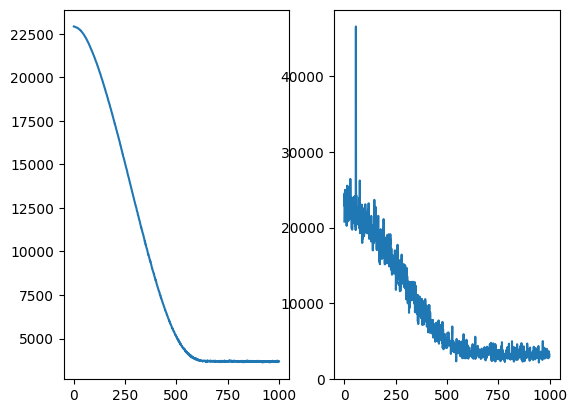

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])

In [ ]:
losses = get_valid_loss(model, data_loader_valid)
print(f'MAE {np.mean(np.abs(losses))}')
print(f'MSE {np.mean((losses) ** 2)}')
print(f'RMSE {np.sqrt(np.mean((losses) ** 2))}')

In [ ]:
from captum.attr import IntegratedGradients

ig = IntegratedGradients(model)

X_test_tensor = torch.tensor(valid_data, dtype=torch.float32)

target_class = 0
def compute_attributions(sample):
    attributions, _ = ig.attribute(sample.unsqueeze(0), target=target_class, return_convergence_delta=True)
    return attributions.squeeze(0).detach().numpy()

attributions = np.array([compute_attributions(sample) for sample in X_test_tensor])

feature_importance = np.mean(np.abs(attributions), axis=0)

plt.bar(range(len(feature_importance)), feature_importance)
plt.xlabel('Feature Index')
plt.ylabel('Importance Score')
plt.title('Feature Importances from Integrated Gradients')
plt.show()

## Gradient Boost

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Example DataFrame (assuming data_raw is defined)
# data_raw = pd.DataFrame(data)

# Split the data into training and validation sets
X = data_raw.iloc[:, :-1]
y = data_raw.iloc[:, -1]

X_train, X_val, y_train, y_val = train_test_split(data_raw.iloc[:, :-1], data_raw.iloc[:, -1], test_size=0.2, random_state=1)

# Initialize the model
model_grad = GradientBoostingRegressor(n_estimators=100)

# Train the model
model_grad.fit(X_train, y_train)

# Predict on the training set
y_train_pred = model_grad.predict(X_train)
train_mse = mean_squared_error(y_train, y_train_pred)

# Predict on the validation set
y_val_pred = model_grad.predict(X_val)
val_mse = mean_squared_error(y_val, y_val_pred)

# Print the errors
print('Training MSE: %.3f' % train_mse)
print('Validation MSE: %.3f' % val_mse)


Training MSE: 3118.943
Validation MSE: 3557.679
